# **TASK 3: Data Visualization**

In [1]:
from google.colab import files
uploaded = files.upload()  # Choose Sales_data.csv

import io
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))
print("Dataset shape:", df.shape)
display(df.head())

Saving Sales_data.csv to Sales_data (1).csv
Dataset shape: (1000, 20)


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating,Month,Year,Day Name
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1,January,2019,Saturday
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6,March,2019,Friday
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4,March,2019,Sunday
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4,January,2019,Sunday
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3,February,2019,Friday


In [2]:
data = df.copy()
for col in ["Unit price", "Quantity", "Tax 5%", "Sales", "cogs", "gross income", "Rating"]:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

if "Date" in data.columns:
    data["Date"] = pd.to_datetime(data["Date"], format="%m/%d/%Y", errors="coerce")
    data["Month Period"] = data["Date"].dt.to_period("M").astype(str)
    data["Day Name Derived"] = data["Date"].dt.day_name()

print("Rows available:", len(data))
display(data.isna().sum().to_frame("Missing values"))

Rows available: 1000


,Missing values
Invoice ID,0
Branch,0
City,0
Customer type,0
Gender,0
Product line,0
Unit price,0
Quantity,0
Tax 5%,0
Sales,0


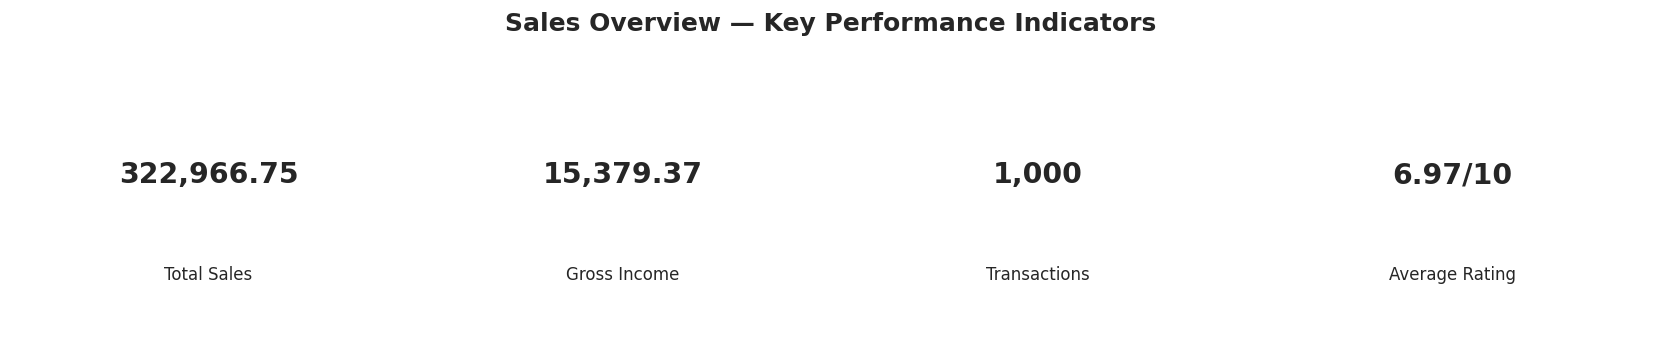

In [3]:
total_sales = data["Sales"].sum()
total_gross_income = data["gross income"].sum() if "gross income" in data else np.nan
transactions = data["Invoice ID"].nunique() if "Invoice ID" in data else len(data)
average_rating = data["Rating"].mean() if "Rating" in data else np.nan

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
items = [
    ("Total Sales", f"{total_sales:,.2f}"),
    ("Gross Income", f"{total_gross_income:,.2f}"),
    ("Transactions", f"{transactions:,.0f}"),
    ("Average Rating", f"{average_rating:.2f}/10"),
]
for ax, (label, value) in zip(axes, items):
    ax.axis("off")
    ax.text(0.5, 0.62, value, ha="center", va="center", fontsize=17, fontweight="bold")
    ax.text(0.5, 0.25, label, ha="center", va="center", fontsize=10)
fig.suptitle("Sales Overview — Key Performance Indicators", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

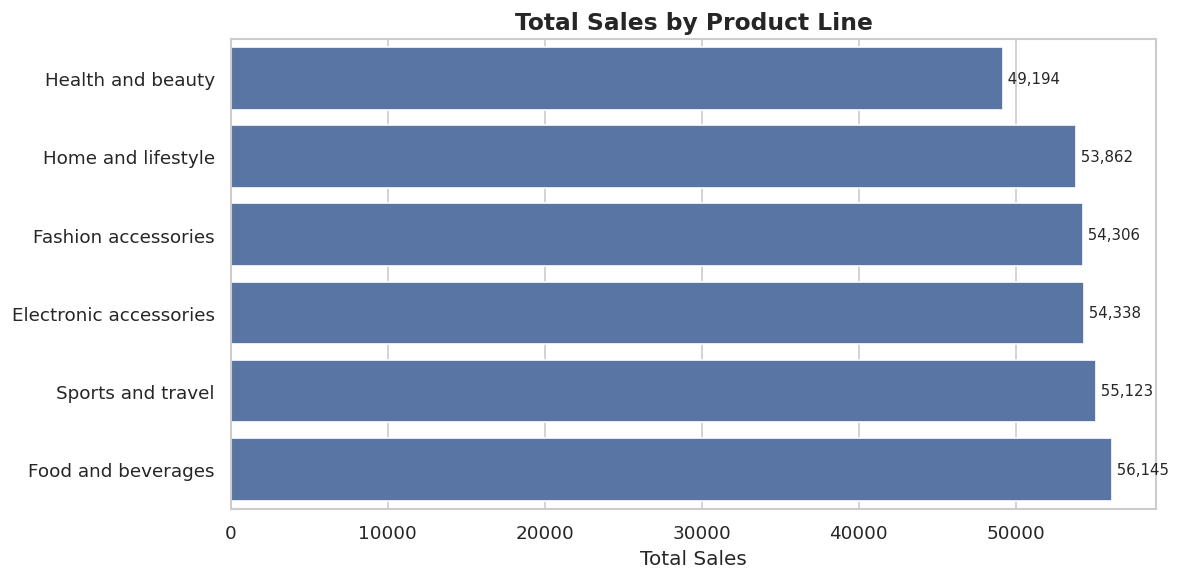

Highest-sales product line: Food and beverages (56,144.84)


In [4]:
product_sales = data.groupby("Product line")["Sales"].sum().sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=product_sales.values, y=product_sales.index, ax=ax)
ax.set_title("Total Sales by Product Line", fontsize=14, fontweight="bold")
ax.set_xlabel("Total Sales")
ax.set_ylabel("")
for i, value in enumerate(product_sales.values):
    ax.text(value, i, f" {value:,.0f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig("sales_by_product_line.png", dpi=300, bbox_inches="tight")
plt.show()
print("Highest-sales product line:", product_sales.idxmax(), f"({product_sales.max():,.2f})")

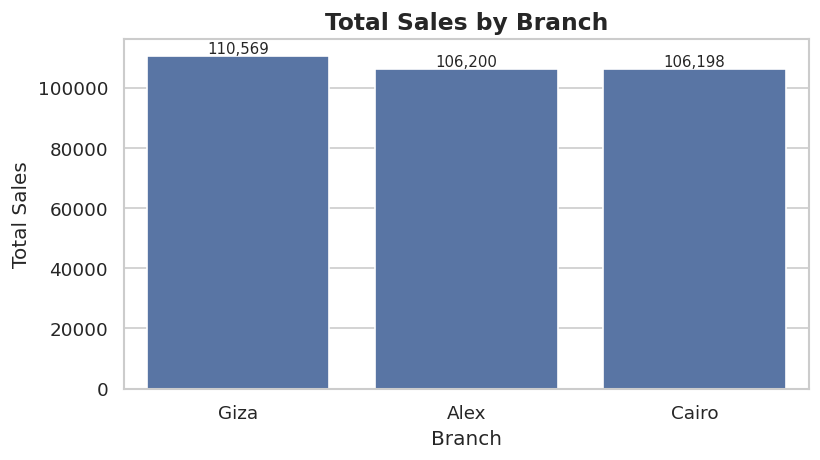

Highest-sales branch: Giza (110,568.71)


In [5]:
branch_sales = data.groupby("Branch")["Sales"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=branch_sales.index, y=branch_sales.values, ax=ax)
ax.set_title("Total Sales by Branch", fontsize=14, fontweight="bold")
ax.set_xlabel("Branch")
ax.set_ylabel("Total Sales")
for i, value in enumerate(branch_sales.values):
    ax.text(i, value, f"{value:,.0f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig("sales_by_branch.png", dpi=300, bbox_inches="tight")
plt.show()
print("Highest-sales branch:", branch_sales.idxmax(), f"({branch_sales.max():,.2f})")

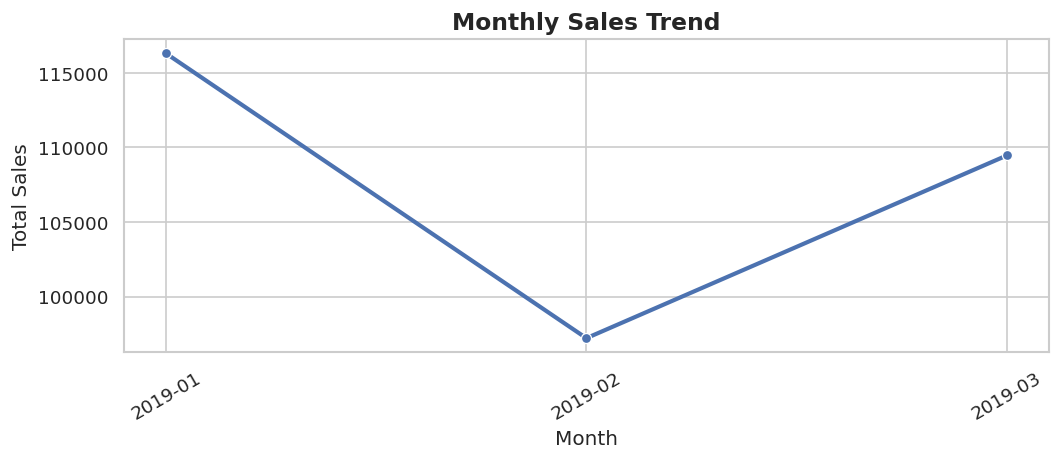

,Total Sales
Date,
2019-01,116291.868
2019-02,97219.374
2019-03,109455.507


In [6]:
monthly_sales = data.dropna(subset=["Date"]).groupby(data["Date"].dt.to_period("M"))["Sales"].sum()
monthly_sales.index = monthly_sales.index.astype(str)
fig, ax = plt.subplots(figsize=(9, 4))
sns.lineplot(x=monthly_sales.index, y=monthly_sales.values, marker="o", linewidth=2.5, ax=ax)
ax.set_title("Monthly Sales Trend", fontsize=14, fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Total Sales")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("monthly_sales_trend.png", dpi=300, bbox_inches="tight")
plt.show()
display(monthly_sales.to_frame("Total Sales"))

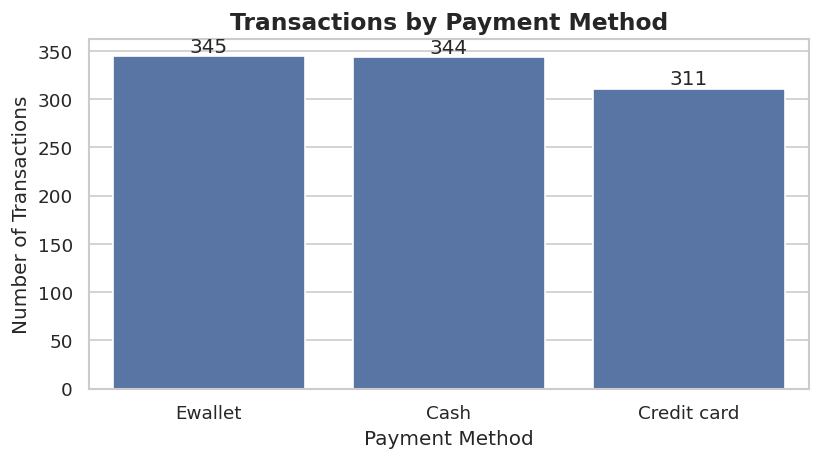

,Transaction Count
Payment,
Ewallet,345
Cash,344
Credit card,311


In [7]:
payment_counts = data["Payment"].value_counts()
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=payment_counts.index, y=payment_counts.values, ax=ax)
ax.set_title("Transactions by Payment Method", fontsize=14, fontweight="bold")
ax.set_xlabel("Payment Method")
ax.set_ylabel("Number of Transactions")
for i, value in enumerate(payment_counts.values):
    ax.text(i, value, str(value), ha="center", va="bottom")
plt.tight_layout()
plt.savefig("payment_method_counts.png", dpi=300, bbox_inches="tight")
plt.show()
display(payment_counts.to_frame("Transaction Count"))

,Transactions,Total_Sales,Average_Sales
Customer type,,,
Member,565,189694.76,335.74
Normal,435,133271.98,306.37


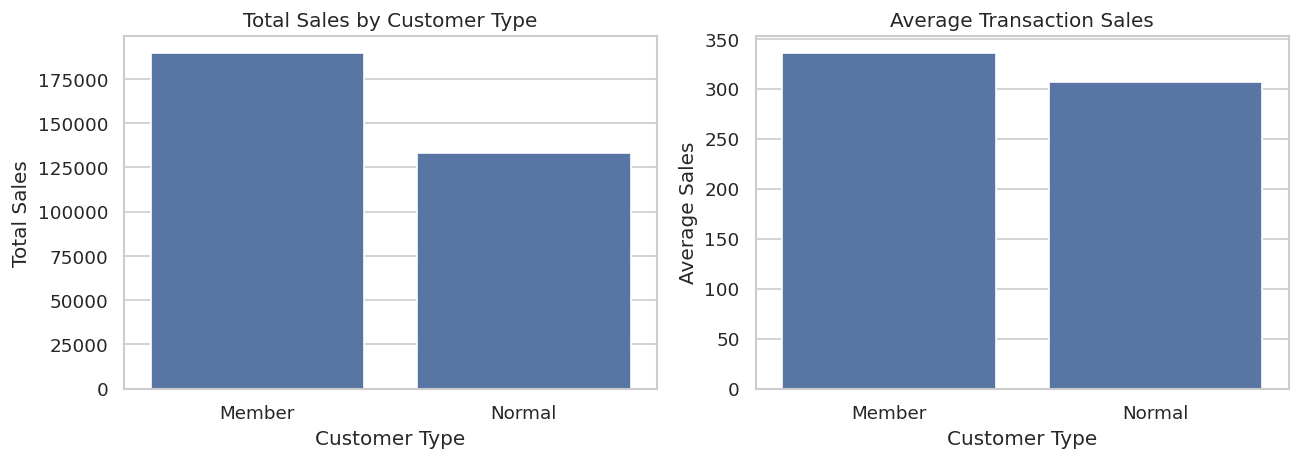

In [8]:
customer_summary = data.groupby("Customer type")["Sales"].agg(
    Transactions="count", Total_Sales="sum", Average_Sales="mean"
)
display(customer_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=data, x="Customer type", y="Sales", estimator="sum", errorbar=None, ax=axes[0])
axes[0].set_title("Total Sales by Customer Type")
axes[0].set_xlabel("Customer Type")
axes[0].set_ylabel("Total Sales")

sns.barplot(data=data, x="Customer type", y="Sales", estimator="mean", errorbar=None, ax=axes[1])
axes[1].set_title("Average Transaction Sales")
axes[1].set_xlabel("Customer Type")
axes[1].set_ylabel("Average Sales")
plt.tight_layout()
plt.savefig("customer_type_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

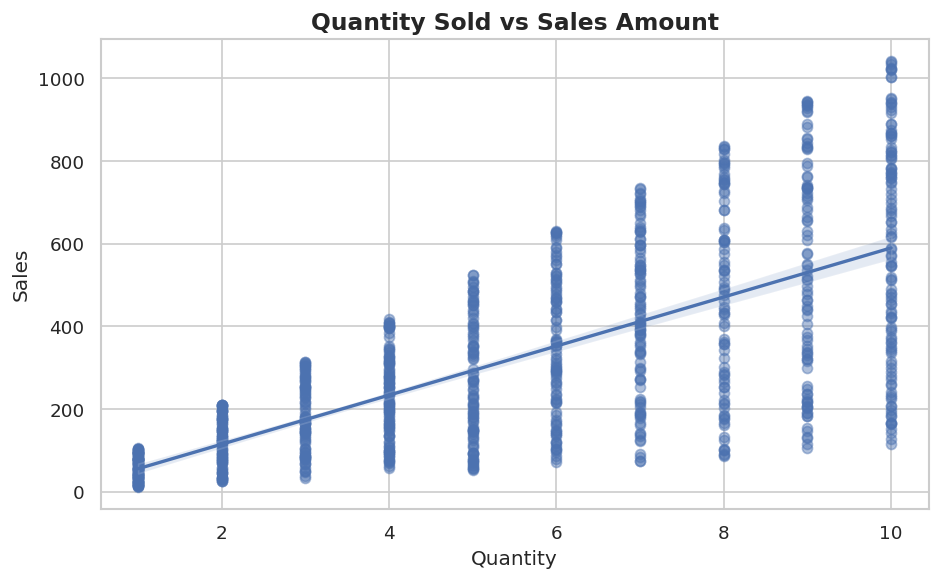

Correlation between Quantity and Sales: 0.706


In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(data=data, x="Quantity", y="Sales",
            scatter_kws={"alpha": 0.45}, line_kws={"linewidth": 2}, ax=ax)
ax.set_title("Quantity Sold vs Sales Amount", fontsize=14, fontweight="bold")
ax.set_xlabel("Quantity")
ax.set_ylabel("Sales")
plt.tight_layout()
plt.savefig("quantity_vs_sales.png", dpi=300, bbox_inches="tight")
plt.show()
print("Correlation between Quantity and Sales:", round(data[["Quantity", "Sales"]].corr().iloc[0, 1], 3))

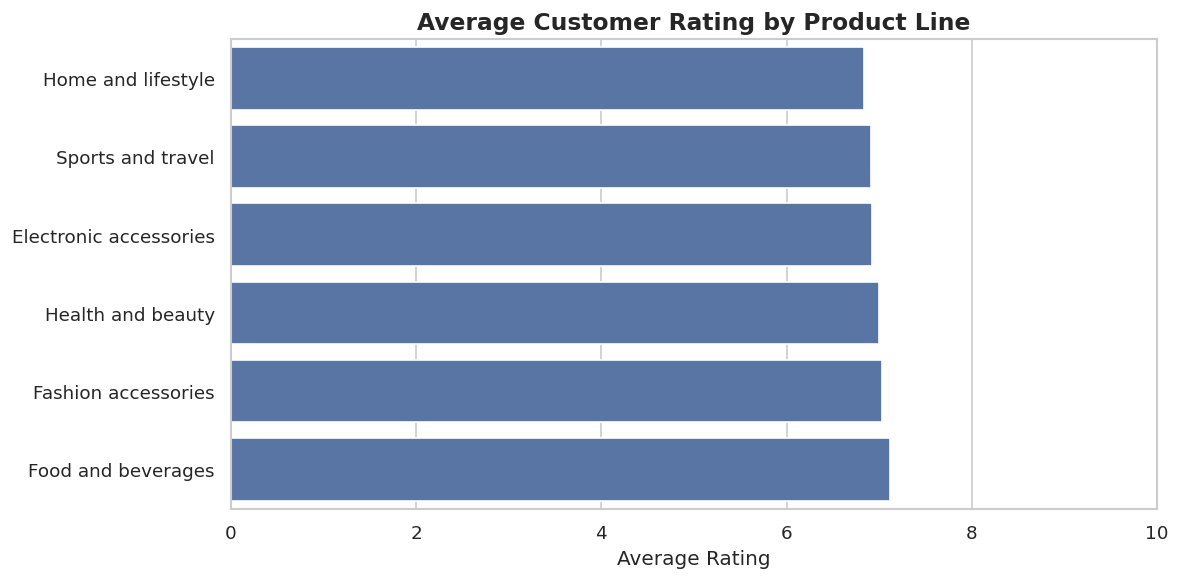

,Average Rating
Product line,
Home and lifestyle,6.84
Sports and travel,6.92
Electronic accessories,6.92
Health and beauty,7.00
Fashion accessories,7.03
Food and beverages,7.11


In [10]:
rating_by_product = data.groupby("Product line")["Rating"].mean().sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=rating_by_product.values, y=rating_by_product.index, ax=ax)
ax.set_title("Average Customer Rating by Product Line", fontsize=14, fontweight="bold")
ax.set_xlabel("Average Rating")
ax.set_ylabel("")
ax.set_xlim(0, 10)
plt.tight_layout()
plt.savefig("average_rating_by_product.png", dpi=300, bbox_inches="tight")
plt.show()
display(rating_by_product.to_frame("Average Rating").round(2))

In [11]:

# Display total sales for all branches
branch_sales = data.groupby("Branch")["Sales"].sum().sort_values(
    ascending=False
)

print("Total sales by branch:")
print(branch_sales.round(2))

print("\nHighest-selling branch:", branch_sales.idxmax())
print("Highest total sales:", round(branch_sales.max(), 2))

print("\nDifference between highest and lowest branches:")
print(round(branch_sales.max() - branch_sales.min(), 2))


Total sales by branch:
Branch
Giza     110568.71
Alex     106200.37
Cairo    106197.67
Name: Sales, dtype: float64

Highest-selling branch: Giza
Highest total sales: 110568.71

Difference between highest and lowest branches:
4371.03


1. **Product insight:** Food and beverages had the highest total sales at 56,144.84. This indicates that it was the best-performing product line in terms of total sales during the observed period.
2. **Branch insight:** Giza had the highest total sales, amounting to 110,568.71. The total sales of Giza should be compared with Alex and the remaining branch to identify the differences in branch performance.
3. **Time insight:** Sales varied over the observed months. Total sales decreased from 116,291.87 in January 2019 to 97,219.37 in February 2019, then increased to 109,455.51 in March 2019. This indicates a decline in February followed by a recovery in March. However, the analysis covers only three months, so it is not sufficient to establish a long-term sales trend.
4. **Payment insight:** Ewallet was the most frequently used payment method, with 345 transactions. Cash was used for 344 transactions, while credit cards were used for 311 transactions. Ewallet was therefore the most popular method, although its usage was only slightly higher than cash.
5. **Customer insight:** Member customers generated total sales of 189,694.76 from 565 transactions, with an average transaction value of 335.74. Normal customers generated total sales of 133,271.98 from 435 transactions, with an average transaction value of 306.37. Members contributed more total sales and had a higher average transaction value than Normal customers.
6. **Rating insight:** Food and beverages had the highest average customer rating, at approximately 7.11 out of 10. This suggests that it received the most favourable average customer ratings among the product lines in the dataset.
7. **Recommendation:** The supermarket should investigate the practices and performance of the Giza branch to identify approaches that could be useful for other branches. It should also maintain the performance of the Food and beverages product line and investigate opportunities to improve lower-sales product lines. Since Member customers generated higher total sales and average transaction values, the supermarket could consider targeted loyalty offers to encourage repeat purchases. These are recommendations based on observed patterns; further investigation is needed to determine the reasons behind the results.